# 05 — Problem Definition, Features and the Leakage Guard

Phase 1 explored three candidate problems and recommended two. This notebook
fixes the scope, defines both targets, builds the Phase 2 feature set, and
**proves** that the new history features cannot see the future.

| | Problem 1 — delivery performance | Problem 2 — satisfaction risk |
|---|---|---|
| Question | How long will this order take, and will it miss its promise? | Will this delivered order draw a 1–2 star review? |
| Prediction moment | `at_checkout` | `at_delivery` |
| Stakeholder | Operations / logistics | Customer experience |
| Framing A | **regression** on lead time in days | **classification** of 1–2 stars |
| Framing B | **classification** of late vs the promised date | — |
| Headline metric | MAE | PR-AUC against the no-skill floor |

The two are one business chain, not two unrelated tasks. Phase 1's strongest
finding was that a late delivery raises the 1–2 star rate from 9.2% to 54.0%.
Problem 1 predicts the delivery before it ships; Problem 2 predicts the damage
before the review lands.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config, evaluate as E, modeling as M
from data_load import load_all, load_analysis
from features import *
from viz import use_report_style, save_fig

use_report_style()
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
RESULTS = ROOT / "report" / "results"
def results(name):
    """Read one canonical result table written by src/train_models.py."""
    p = RESULTS / name
    assert p.exists(), f"{p} missing - run `python src/train_models.py` first"
    return pd.read_csv(p)
print("seed", config.SEED, "| window", config.ANALYSIS_START.date(), "->", config.ANALYSIS_END.date())

seed 42 | window 2017-01-01 -> 2018-08-31


## 5.1 The analysis frame

`build_features(..., with_history=True)` is the Phase 2 entry point. The default
is `False` so that `src/report_stats.py` keeps reproducing the submitted Phase 1
numbers column for column — verified in section 5.6.

In [2]:
tables = load_all()
df = build_features(load_analysis(tables), with_history=True)
sp = make_splits(df)

print(f"analysis window   {len(df):,} orders")
for k in ("train", "val", "test"):
    part = sp[k]
    print(f"  {k:6s} {len(part):6,}   "
          f"{part['order_purchase_timestamp'].min().date()} -> "
          f"{part['order_purchase_timestamp'].max().date()}")
print(f"\ncustomers straddling train and test, removed from the clean test set: "
      f"{sp['n_straddling_customers']:,}")

analysis window   99,091 orders
  train  73,008   2017-01-05 -> 2018-04-29
  val    13,156   2018-04-30 -> 2018-06-29
  test   12,927   2018-06-30 -> 2018-08-30

customers straddling train and test, removed from the clean test set: 227


## 5.2 The two targets, and what they are worth predicting

Both are imbalanced, and both are imbalanced *differently in different periods* —
which turns out to matter more than the imbalance itself (notebook 09).

In [3]:
rates = pd.DataFrame({
    k: {"late (%)": 100 * sp[k]["target_is_late"].mean(),
        "low review (%)": 100 * sp[k]["target_low_review"].mean(),
        "n": len(sp[k])}
    for k in ("train", "val", "test")}).T
rates["always-predict-majority accuracy, late"] = 1 - rates["late (%)"] / 100
rates["always-predict-majority accuracy, review"] = 1 - rates["low review (%)"] / 100
display(rates.round(3))

print("\nThe trap the brief warns about, stated numerically:")
print(f"  a rule that always says 'on time'     scores "
      f"{1 - sp['test']['target_is_late'].mean():.3f} accuracy and catches 0 late orders")
print(f"  a rule that always says 'satisfied'   scores "
      f"{1 - sp['test']['target_low_review'].mean():.3f} accuracy and catches 0 complaints")

,late (%),low review (%),n,"always-predict-majority accuracy, late","always-predict-majority accuracy, review"
train,8.841,15.832,73008.0,0.912,0.842
val,4.970,11.364,13156.0,0.950,0.886
test,7.411,11.031,12927.0,0.926,0.890



The trap the brief warns about, stated numerically:
  a rule that always says 'on time'     scores 0.926 accuracy and catches 0 late orders
  a rule that always says 'satisfied'   scores 0.890 accuracy and catches 0 complaints


## 5.3 Feature sets, by prediction moment

Phase 1 fixed 25 features. Phase 2 adds eight **history** features — a seller's,
a route's and the platform's track record — taking the checkout set to 33 and the
at-delivery set to 36.

In [4]:
sets = pd.DataFrame([
    {"feature set": "MODEL_FEATURES (Phase 1)", "regime": "at_checkout",
     "n": len(MODEL_FEATURES)},
    {"feature set": "CHECKOUT_FEATURES (Phase 2)", "regime": "at_checkout",
     "n": len(CHECKOUT_FEATURES)},
    {"feature set": "DELIVERY_FEATURES (Phase 2)", "regime": "at_delivery",
     "n": len(DELIVERY_FEATURES)},
])
display(sets)

groups = {"calendar": ["purchase_month", "purchase_dow", "purchase_hour", "is_weekend",
                       "is_business_hours", "is_nov_peak"],
          "basket and money": ["n_items", "n_sellers", "log_price", "price_per_item",
                               "total_freight", "freight_ratio", "log_weight",
                               "max_volume_cm3", "total_photos", "max_installments",
                               "is_multi_seller"],
          "geography": ["log_distance", "same_state", "customer_state", "seller_region"],
          "the promise": ["estimated_days", "long_promise"],
          "catalogue": ["lead_category", "lead_payment_type"],
          "history (new)": HISTORY_FEATURES,
          "delivery outcome (at_delivery only)": config.DELIVERY_OUTCOME_FEATURES}
for g, cols in groups.items():
    print(f"  {g:38s} {len(cols):2d}   {', '.join(cols[:4])}"
          + (" ..." if len(cols) > 4 else ""))

,feature set,regime,n
0,MODEL_FEATURES (Phase 1),at_checkout,25
1,CHECKOUT_FEATURES (Phase 2),at_checkout,33
2,DELIVERY_FEATURES (Phase 2),at_delivery,36


  calendar                                6   purchase_month, purchase_dow, purchase_hour, is_weekend ...
  basket and money                       11   n_items, n_sellers, log_price, price_per_item ...
  geography                               4   log_distance, same_state, customer_state, seller_region
  the promise                             2   estimated_days, long_promise
  catalogue                               2   lead_category, lead_payment_type
  history (new)                           8   hist_seller_lead_days, hist_seller_late_rate, hist_seller_low_review_rate, hist_seller_n ...
  delivery outcome (at_delivery only)     3   delivery_days, delay_vs_estimate_days, is_late


## 5.4 The history features, and the trap inside them

A seller's track record is the strongest thing a marketplace knows about an order
at checkout. It is also the easiest place in this project to leak, because of one
distinction that is easy to miss:

> **"Past" means the earlier order had *closed* before this one was placed** —
> not merely that it was placed earlier.

A parcel bought last week that has not yet arrived has no lead time yet. Ordering
the history by *purchase* time would let every order average in outcomes that had
not happened. `add_history()` therefore does an as-of join against the moment each
earlier outcome became observable: `order_delivered_customer_date` for delivery,
`review_creation_date` for reviews.

In [5]:
display(df[HISTORY_FEATURES].describe().T[["count", "mean", "std", "min", "max"]].round(3))

print("missing after the seller -> route -> state -> platform fallback chain:")
print((df[HISTORY_FEATURES].isna().mean() * 100).round(2).to_string())
print(f"\norders with a real seller track record (n >= {config.MIN_HISTORY}): "
      f"{100 * (df['hist_seller_n'] >= config.MIN_HISTORY).mean():.1f}%")
print(f"median number of prior orders behind a seller estimate: "
      f"{df['hist_seller_n'].median():.0f}")

,count,mean,std,min,max
hist_seller_lead_days,99008.0,12.034,3.109,2.510,39.636
hist_seller_late_rate,99008.0,0.054,0.055,0.000,1.000
hist_seller_low_review_rate,98256.0,0.131,0.082,0.000,1.000
hist_seller_n,99091.0,166.444,280.950,0.000,1780.000
hist_route_lead_days,99008.0,12.185,3.975,2.223,36.209
hist_category_low_review_rate,98151.0,0.138,0.049,0.000,0.600
hist_platform_lead_days,99008.0,12.654,2.179,5.225,17.113
hist_platform_late_rate,99008.0,0.075,0.053,0.000,0.219


missing after the seller -> route -> state -> platform fallback chain:
hist_seller_lead_days            0.08
hist_seller_late_rate            0.08
hist_seller_low_review_rate      0.84
hist_seller_n                    0.00
hist_route_lead_days             0.08
hist_category_low_review_rate    0.95
hist_platform_lead_days          0.08
hist_platform_late_rate          0.08

orders with a real seller track record (n >= 5): 83.9%
median number of prior orders behind a seller estimate: 49


### The proof

Rebuild `hist_seller_lead_days` from first principles for a random sample of
orders: filter every earlier order by hand and average the ones that had already
been delivered. The as-of join and the brute-force recomputation must agree
exactly.

The same check runs in `tests/test_leakage.py`, so it is part of the build rather
than a one-off.

In [6]:
rng = np.random.default_rng(config.SEED)
pool = df[df["hist_seller_n"] >= config.MIN_HISTORY].index.to_numpy()
sample = rng.choice(pool, size=150, replace=False)
src = df[["lead_seller_id", "order_purchase_timestamp",
          "order_delivered_customer_date", "delivery_days"]]

checked = mismatched = 0
for idx in sample:
    row = df.loc[idx]
    prior = src[(src["lead_seller_id"] == row["lead_seller_id"])
                & (src["order_delivered_customer_date"] < row["order_purchase_timestamp"])
                ]["delivery_days"].dropna()
    if len(prior) < config.MIN_HISTORY:
        continue
    checked += 1
    mismatched += not np.isclose(prior.mean(), row["hist_seller_lead_days"], atol=1e-9)

print(f"{checked} orders recomputed by hand, {mismatched} disagreements")
assert mismatched == 0, "the history features are looking into the future"

# A second, independent check: a feature built from the future would track the
# CURRENT month's performance better than the previous one. It must lag.
monthly = df.dropna(subset=["delivery_days"]).groupby(
    df["order_purchase_timestamp"].dt.to_period("M")).agg(
    actual=("delivery_days", "mean"), tracked=("hist_platform_lead_days", "mean"))
lag1 = monthly["tracked"].corr(monthly["actual"].shift(1))
same = monthly["tracked"].corr(monthly["actual"])
print(f"corr(platform history, previous month) = {lag1:.3f}")
print(f"corr(platform history, current month)  = {same:.3f}")
assert lag1 > same, "the platform history is anticipating rather than lagging"

150 orders recomputed by hand, 0 disagreements
corr(platform history, previous month) = 0.803
corr(platform history, current month)  = 0.431


### What the platform tracker sees

`hist_platform_lead_days` is a 28-day trailing mean, not an expanding one. An
average over all history would say 13 days while the current month says 8 — it
would encode the *past* level rather than the *current* one, which is precisely
what a drifting series makes useless.

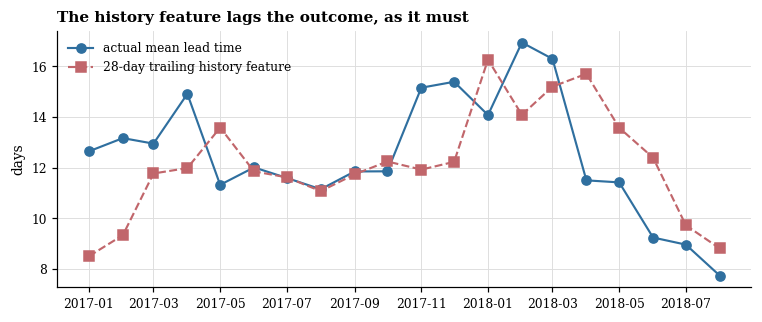

platform tracker range: 5.2 to 17.1 days


In [7]:
fig, ax = plt.subplots(figsize=(config.FIG_WIDTH, 3.0))
m = monthly.reset_index()
m["order_purchase_timestamp"] = m["order_purchase_timestamp"].dt.to_timestamp()
ax.plot(m["order_purchase_timestamp"], m["actual"], "o-",
        color=config.PALETTE["primary"], label="actual mean lead time")
ax.plot(m["order_purchase_timestamp"], m["tracked"], "s--",
        color=config.PALETTE["accent"], label="28-day trailing history feature")
ax.set_ylabel("days"); ax.set_title("The history feature lags the outcome, as it must", loc="left")
ax.legend(); fig.tight_layout(); plt.show()

print(f"platform tracker range: {df['hist_platform_lead_days'].min():.1f} "
      f"to {df['hist_platform_lead_days'].max():.1f} days")

## 5.5 The leakage guard, per prediction moment

Phase 1 established that leakage is not one rule but one rule *per prediction
moment*. `assert_no_leakage(features, regime)` is the gate; every modelling cell
in notebooks 06–09 passes through it.

In [8]:
for name, feats, regime in [
    ("CHECKOUT_FEATURES", CHECKOUT_FEATURES, "at_checkout"),
    ("DELIVERY_FEATURES", DELIVERY_FEATURES, "at_delivery"),
]:
    assert_no_leakage(feats, regime)
    print(f"  OK   {name:20s} @ {regime}")

# And the guard has to bite, or it is decoration.
for bad, regime in [("delivery_days", "at_checkout"), ("review_score", "at_delivery")]:
    try:
        assert_no_leakage(CHECKOUT_FEATURES + [bad], regime)
        raise SystemExit(f"the guard let {bad} through at {regime}")
    except ValueError as exc:
        print(f"  OK   rejected  {bad:22s} @ {regime}")

  OK   CHECKOUT_FEATURES    @ at_checkout
  OK   DELIVERY_FEATURES    @ at_delivery
  OK   rejected  delivery_days          @ at_checkout
  OK   rejected  review_score           @ at_delivery


## 5.6 Phase 1 still reproduces

The Phase 2 additions must not perturb a single number in the submitted Phase 1
report. `with_history=False` is the default for exactly this reason.

In [9]:
p1 = build_features(load_analysis(tables))
assert not (set(HISTORY_FEATURES) & set(p1.columns)), "history leaked into the Phase 1 path"
shared = [c for c in p1.columns if c in df.columns]
identical = [c for c in shared if p1[c].equals(df[c])]
print(f"{len(identical)} of {len(shared)} shared columns are byte-identical")
assert len(identical) == len(shared), [c for c in shared if c not in identical]
print("Phase 1 reproduces exactly.")

67 of 67 shared columns are byte-identical
Phase 1 reproduces exactly.


## 5.7 Scoping checklist, closed out

| Criterion | Problem 1 (delivery) | Problem 2 (low review) |
|---|---|---|
| Derivable target | yes, from order timestamps | yes, `review_score <= 2` |
| Realistic features | yes, `at_checkout` regime, guard enforced | yes, `at_delivery` regime |
| Sufficient signal | Phase 1: −41% MAE against a constant | Phase 1: PR-AUC 3.6× the floor |
| Manageable imbalance | 7–8% late; PR-AUC + threshold tuning | 11–15% low; same handling |
| Clear stakeholder | operations, re-quote or expedite | customer experience, outreach |

Both pass. Notebooks 06–09 build them.